In [84]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import mne

import glob
import os
import sys
from scipy.io import savemat, loadmat
from scipy.stats import pearsonr, spearmanr, sem
from statsmodels.stats.multitest import fdrcorrection
import scipy.stats as stats
from pingouin import rm_anova

import matplotlib as mpl
plt.style.use("article.mplstyle")

from statannotations.Annotator import Annotator

from mne.stats import permutation_cluster_1samp_test

sys.path.append('../utils')
from ERP_utils import *
from update_sub_lists import*
from plot_utils import *
mne.set_log_level('CRITICAL')



### TO DO: 

make this notebook handle the pre and post data at once without manually setting the period each time
also different musician levels

### Set up 

In [ ]:
#plotting parameters
firsts_color = 'teal'
others_color = 'coral'

In [86]:
#-----------------------------
#           LOADING FILES AND INITIALIZING DIRECTORIES
#-----------------------------

#use MIDI folders or audio folders to change triggers
epochs_dir = '../analysis_error/error_epochs_data_n05to05_30Hz_corrected'


#channels and times for plotting
# ch_names_64, ch_names_72 = load_channels()
erp_times = create_erp_times(-0.5,0.5, 128)

good_listen_subjects, good_motor_subjects, good_error_subjects, musicians, nonmusicians = load_subject_lists_LME()
subjects_to_process =  good_error_subjects


In [87]:
def load_error_epochs_bysubject(epochs_dir, subjects_to_process, epoch_type, sub_ave = True):
    """ 
    Loads the epochs for error trials
    subjects_to_process: list of subjects where each element is a string. e.g. ['01', '02']
    epoch_type: which error keystrokes are included. Currently 'all', 'inv', 'shinv' and 'norm'
        ---future: separate keystrokes that are the first keystroke after a map change from all the other keystrokes
    sub_ave: averages over channels
    ---
    Returns a dataframe with columns 'subject', 'period', 'musician', and 'epoch_type'.
        each row of ['epochs'] is an array of shape n_channels x n_timepoints, and is the average of all epochs from one subject
    
    """

    epochs_df = pd.DataFrame(columns = ['subject', 'period', 'musician', 'epochtype', 'epochs'])
    good_listen_subjects, good_motor_subjects, musicians, nonmusicians = load_subject_lists()

    assert isinstance (subjects_to_process, list)

    for subject in subjects_to_process:
        print('Processing subject: ', subject)

        if subject in musicians: 
            musician = 1
        else: 
            musician = 0
        for period in ['pre', 'post']:
            file_epochs_pre = glob.glob(os.path.join(epochs_dir, f'error_epochs_{epoch_type}_{period}_{subject}.fif'))[0]
            epochs_sub = mne.read_epochs(file_epochs_pre)

            if sub_ave:
                epochs_sub = np.mean(epochs_sub.get_data()[:, :64, :], axis = 0) #get only the eeg channels and average all trials per subject
            else: 
                #epochs_sub = epochs_sub.get_data()[:, :64, :]
                epochs_sub = epochs_sub.get_data()

            df_sub = pd.DataFrame({
                'subject': subject,
                'period' : period,
                'musician' : musician,
                'epochtype': epoch_type,
                'epochs': [epochs_sub]
            })
            epochs_df = pd.concat([epochs_df, df_sub])


    epochs_df.reset_index(drop=True, inplace=True)
    return (epochs_df)


In [88]:
epochs_df_all = load_error_epochs_bysubject(epochs_dir, subjects_to_process, 'all', sub_ave=False)
epochs_df_inv = load_error_epochs_bysubject(epochs_dir, subjects_to_process, 'inv', sub_ave = False)
epochs_df_shinv = load_error_epochs_bysubject(epochs_dir, subjects_to_process, 'shinv', sub_ave = False)
epochs_df_norm = load_error_epochs_bysubject(epochs_dir, subjects_to_process, 'norm', sub_ave = False)

epochs_df_firsts = load_error_epochs_bysubject(epochs_dir, subjects_to_process, 'firsts', sub_ave=False)
epochs_df_others = load_error_epochs_bysubject(epochs_dir, subjects_to_process, 'others', sub_ave=False)


Processing subject:  01
Processing subject:  04
Processing subject:  05
Processing subject:  06
Processing subject:  07
Processing subject:  08
Processing subject:  09
Processing subject:  10
Processing subject:  11
Processing subject:  12
Processing subject:  13
Processing subject:  14
Processing subject:  15
Processing subject:  16
Processing subject:  17
Processing subject:  18
Processing subject:  19
Processing subject:  20
Processing subject:  01
Processing subject:  04
Processing subject:  05
Processing subject:  06
Processing subject:  07
Processing subject:  08
Processing subject:  09
Processing subject:  10
Processing subject:  11
Processing subject:  12
Processing subject:  13
Processing subject:  14
Processing subject:  15
Processing subject:  16
Processing subject:  17
Processing subject:  18
Processing subject:  19
Processing subject:  20
Processing subject:  01
Processing subject:  04
Processing subject:  05
Processing subject:  06
Processing subject:  07
Processing subje

## ERPs by map

In [89]:
def find_evokeds(epochs_df, column_to_ave = 'epochs', ev_col_name = 'evokeds'):
    """ 
    Takes a dataframe with columns 'subject', 'period', 'musician', 'epochtype', 'epochs'
    Returns mean and sem of epochs for each subject
    """
    #if 'evokeds' not in epochs_df.columns:
    epochs_df[ev_col_name] = epochs_df[column_to_ave].apply(lambda x: np.mean(x, axis = 0))
    return epochs_df

def find_mean_sem_eps(epochs_df, ch_idx, col_to_ave = 'epochs'):
    """ 
    Takes a dataframe with columns 'subject', 'period', 'musician', 'epochtype', 'epochs'
    Returns mean and sem of epochs for each subject
    """
    if col_to_ave == 'epochs' and 'evokeds' not in epochs_df.columns:
        epochs_df['evokeds'] = epochs_df[col_to_ave].apply(lambda x: np.mean(x, axis = 0))
        mean_ev = epochs_df['evokeds'].mean(axis=0)[ch_idx].flatten()   
        sem_ev = sem(epochs_df['evokeds'],axis=0)[ch_idx].flatten()
    
    else:
        epochs_df[col_to_ave+'_evokeds'] = epochs_df[col_to_ave].apply(lambda x: np.mean(x, axis = 0))
        mean_ev = epochs_df[col_to_ave+'evokeds'].mean(axis=0)[ch_idx].flatten()   
        sem_ev = sem(epochs_df[col_to_ave+'evokeds'],axis=0)[ch_idx].flatten()

        

    return mean_ev, sem_ev
    


In [90]:
def find_mean_sem_eps(epochs_df, ch_idx, col_to_ave='epochs', data = 'epochs'):
    """ 
    Takes a dataframe with columns 'subject', 'period', 'musician', 'epochtype', 'epochs'
    Returns mean and sem of epochs for each subject
    """
    # evoked_col = f'{col_to_ave}_evokeds'
    
    if 'evokeds' not in epochs_df.columns:

        epochs_df['evokeds'] = epochs_df[col_to_ave].apply(lambda x: np.mean(x, axis=0))
    
    mean_ev = epochs_df['evokeds'].mean(axis=0)[ch_idx].flatten()
    sem_ev = sem(np.stack(epochs_df['evokeds'].values), axis=0)[ch_idx].flatten()
    
    return mean_ev, sem_ev

def find_mean_sem_evs(epochs_df, ch_idx, col_to_ave):
    mean_ev = epochs_df[col_to_ave].mean(axis=0)[ch_idx].flatten()
    sem_ev = sem(np.stack(epochs_df[col_to_ave].values), axis=0)[ch_idx].flatten()
    
    return mean_ev, sem_ev

def plot_mean_sem(times, mean, sem, color, label):
    plt.plot(times, mean, color=color, label=label)
    plt.fill_between(times, mean - sem, mean + sem, color=color, alpha=0.3)


def config_erp_plot(axis_fontsize=20, tick_fontsize=15, linewidth = 1):
    plt.xlabel('Time (s)', fontsize=axis_fontsize)
    plt.ylabel('Amplitude (µV)', fontsize=axis_fontsize)
   
    
    # Draw reference lines
    plt.hlines(0, -0.5, 0.5, color='black', linewidth=linewidth)
    plt.vlines(0, -6.5e-6, 5e-6, color='black', linewidth=linewidth)
    
    # Format y-axis values in µV instead of scientific notation
    plt.ticklabel_format(style='plain', axis='y')
    plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x * 1e6:.1f}'))
    
    # Set axis limits
    plt.xlim(-0.1, 0.45)
    plt.ylim(-6.5e-6, 5e-6)
    
    # Set tick font sizes
    plt.xticks(fontsize=tick_fontsize)
    plt.yticks(fontsize=tick_fontsize)
    
    # Set legend font size
    # plt.legend(fontsize=xtick_fontsize)


/var/folders/jq/t9k2fgpx515flrs5403k2gf80000gn/T/ipykernel_87483/265199111.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  epochs_df['evokeds'] = epochs_df[col_to_ave].apply(lambda x: np.mean(x, axis=0))
/var/folders/jq/t9k2fgpx515flrs5403k2gf80000gn/T/ipykernel_87483/265199111.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  epochs_df['evokeds'] = epochs_df[col_to_ave].apply(lambda x: np.mean(x, axis=0))
/var/folders/jq/t9k2fgpx515flrs5403k2gf80000gn/T/ipykernel_87483/265199111.py:10: SettingWithC

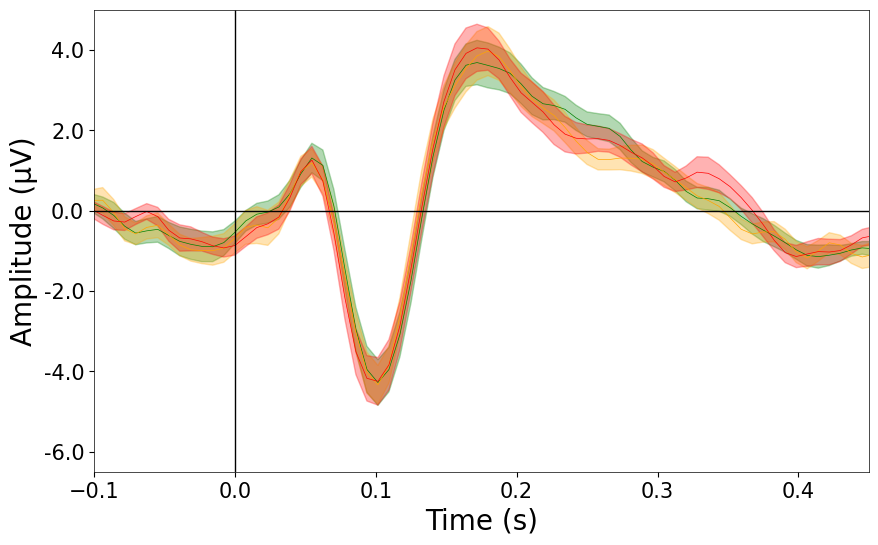

In [ ]:
#plot ALL ERPs by map per period
ch_idx = ch_index(['Fz'])
period= 'pre'

mean_all, sem_all = find_mean_sem_eps(epochs_df_all, ch_idx)
mean_inv, sem_inv = find_mean_sem_eps(epochs_df_inv.query(f'period == "{period}"'), ch_idx)
mean_shinv, sem_shinv = find_mean_sem_eps(epochs_df_shinv.query(f'period == "{period}"'), ch_idx)
mean_norm, sem_norm = find_mean_sem_eps(epochs_df_norm.query(f'period == "{period}"'), ch_idx)

plt.figure(figsize=(10, 6))

#plot_mean_sem(erp_times, mean_all, sem_all, color='black', label='all')
plot_mean_sem(erp_times, mean_inv, sem_inv, color='green', label='inv')
plot_mean_sem(erp_times, mean_shinv, sem_shinv, color='orange', label='shinv')
plot_mean_sem(erp_times, mean_norm, sem_norm, color='red', label='norm')

config_erp_plot()

# plt.title(f'ERP by map, {period}', fontsize=axis_fontsize)
# plt.savefig(f'./figs/erp_by_map_{period}.svg')


In [92]:
#aggregate all the epochs into one df

#calculate evokeds 
epochs_df_inv = find_evokeds(epochs_df_inv)
epochs_df_shinv = find_evokeds(epochs_df_shinv)
epochs_df_norm = find_evokeds(epochs_df_norm)

epochs_df_bymap = pd.merge(
    pd.merge(
        epochs_df_inv,
        epochs_df_shinv,
        on=['subject', 'period', 'musician'],
        suffixes=('_inv', '_shinv')
    ),
    epochs_df_norm,
    on=['subject', 'period', 'musician'],
    suffixes=('', '_norm')
)




In [93]:
def peak_regions_max(x, ch_idx, t_idx):
    x_ch_mean = np.mean(x[ch_idx], axis =0)
    x_ch_time_max = np.max(x_ch_mean[t_idx[0]:t_idx[1]])
    return x_ch_time_max

def peak_regions_min(x, ch_idx, t_idx):
    x_ch_mean = np.mean(x[ch_idx], axis =0)
    x_ch_time_max = np.min(x_ch_mean[t_idx[0]:t_idx[1]])
    return x_ch_time_max


def peak_regions_custom(x, ch_idx, t_idx, peak_type):
    x_ch_mean = np.mean(x[ch_idx], axis =0)
    x_ch_time_peak = peak_type(x_ch_mean[t_idx[0]:t_idx[1]])
    return x_ch_time_peak

In [94]:
#select timepoints and channels of interest
ch_to_test = ['Fz', 'FCz', 'Cz', 'F1', 'FC1', 'C1', 'C2', 'FC2', 'F2']
# time_to_plot = [0.08, 0.12]
# time_to_plot = [0.055, 0.065]
time_to_plot = [0.325, 0.375]

ch_idx = ch_index(ch_to_test)
time_idx = time_index_custom(time_to_plot, erp_times)

epochs_df_bymap['amp_inv'] = epochs_df_bymap['evokeds_inv'].apply(lambda x: peak_regions_max(x, ch_idx, time_idx))
epochs_df_bymap['amp_shinv'] = epochs_df_bymap['evokeds_shinv'].apply(lambda x: peak_regions_max(x, ch_idx, time_idx))
epochs_df_bymap['amp_norm'] = epochs_df_bymap['evokeds'].apply(lambda x: peak_regions_max(x, ch_idx, time_idx))

#format df to be plotted using sns
epochs_df_bymap_sns = pd.melt(epochs_df_bymap, id_vars=['subject', 'period', 'musician'], value_vars=['amp_inv', 'amp_shinv', 'amp_norm'], var_name='map', value_name='amplitude')
epochs_df_bymap_sns['amplitude'] = epochs_df_bymap_sns['amplitude'].apply(lambda x: x[0] if isinstance(x, list) else x).astype(float)


## Firsts by map 

In [96]:
def find_firsts_bymap(epochs_df_map, epochs_df_firsts):
    firsts_map = []
    assert len(epochs_df_map) == len(epochs_df_firsts), 'both dataframes must have the same length'
    for i in range(len(epochs_df_map)):
        ep_map = epochs_df_map['epochs'].iloc[i]
        ep_firsts = epochs_df_firsts['epochs'].iloc[i]
        firsts = np.array([row for row in ep_map if any(np.array_equal(row, r) for r in ep_firsts)])
        firsts_map.append(firsts)

    epochs_filt = epochs_df_map[[
        'subject', 'period', 'musician'
    ]].copy()
    
    epochs_filt['epochs'] = firsts_map
    return epochs_filt

In [97]:
epochs_df_firstinv = find_firsts_bymap(epochs_df_inv, epochs_df_firsts)
epochs_df_firstshinv = find_firsts_bymap(epochs_df_shinv, epochs_df_firsts)
epochs_df_firstnorm = find_firsts_bymap(epochs_df_norm, epochs_df_firsts)

/var/folders/jq/t9k2fgpx515flrs5403k2gf80000gn/T/ipykernel_87483/265199111.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  epochs_df['evokeds'] = epochs_df[col_to_ave].apply(lambda x: np.mean(x, axis=0))
/var/folders/jq/t9k2fgpx515flrs5403k2gf80000gn/T/ipykernel_87483/265199111.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  epochs_df['evokeds'] = epochs_df[col_to_ave].apply(lambda x: np.mean(x, axis=0))
/var/folders/jq/t9k2fgpx515flrs5403k2gf80000gn/T/ipykernel_87483/265199111.py:10: SettingWithC

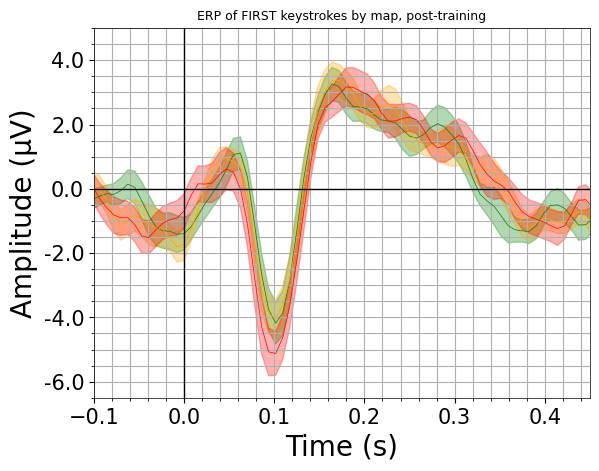

In [ ]:
period = 'post'
ch_to_plot = ['Fz']
ch_idx = ch_index(ch_to_plot)

mean_invfirst, sem_invfirst = find_mean_sem_eps(epochs_df_firstinv.query(f'period == "{period}"'), ch_idx)
mean_shinvfirst, sem_shinvfirst = find_mean_sem_eps(epochs_df_firstshinv.query(f'period == "{period}"'), ch_idx)
mean_normfirst, sem_normfirst = find_mean_sem_eps(epochs_df_firstnorm.query(f'period == "{period}"'), ch_idx)

plot_mean_sem(erp_times, mean_invfirst, sem_invfirst, color='green', label='inv')
plot_mean_sem(erp_times, mean_shinvfirst, sem_shinvfirst, color='orange', label='shinv')
plot_mean_sem(erp_times, mean_normfirst, sem_normfirst, color='red', label='norm')

config_erp_plot()
plt.title(f'ERP of FIRST keystrokes by map, {period}-training')
plt.minorticks_on()

/var/folders/jq/t9k2fgpx515flrs5403k2gf80000gn/T/ipykernel_87483/265199111.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  epochs_df['evokeds'] = epochs_df[col_to_ave].apply(lambda x: np.mean(x, axis=0))
/var/folders/jq/t9k2fgpx515flrs5403k2gf80000gn/T/ipykernel_87483/265199111.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  epochs_df['evokeds'] = epochs_df[col_to_ave].apply(lambda x: np.mean(x, axis=0))
/var/folders/jq/t9k2fgpx515flrs5403k2gf80000gn/T/ipykernel_87483/265199111.py:10: SettingWithC

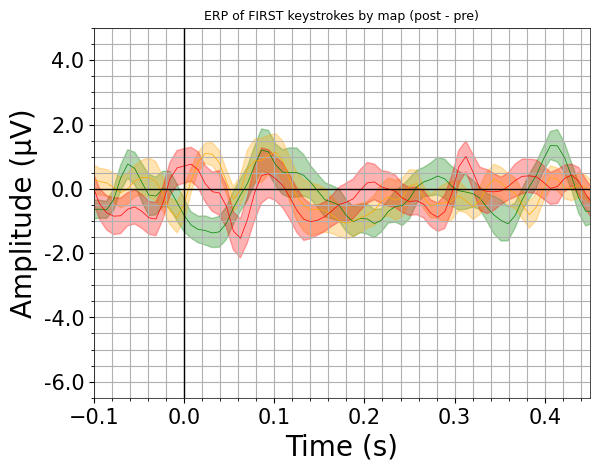

In [ ]:
ch_to_plot = ['Fz']
ch_idx = ch_index(ch_to_plot)

# --- inv ---
mean_pre_inv, sem_pre_inv = find_mean_sem_eps(
    epochs_df_firstinv.query('period == "pre"'), ch_idx
)
mean_post_inv, sem_post_inv = find_mean_sem_eps(
    epochs_df_firstinv.query('period == "post"'), ch_idx
)
mean_diff_inv = mean_post_inv - mean_pre_inv

# --- shinv ---
mean_pre_shinv, sem_pre_shinv = find_mean_sem_eps(
    epochs_df_firstshinv.query('period == "pre"'), ch_idx
)
mean_post_shinv, sem_post_shinv = find_mean_sem_eps(
    epochs_df_firstshinv.query('period == "post"'), ch_idx
)
mean_diff_shinv = mean_post_shinv - mean_pre_shinv

# --- norm ---
mean_pre_norm, sem_pre_norm = find_mean_sem_eps(
    epochs_df_firstnorm.query('period == "pre"'), ch_idx
)
mean_post_norm, sem_post_norm = find_mean_sem_eps(
    epochs_df_firstnorm.query('period == "post"'), ch_idx
)
mean_diff_norm = mean_post_norm - mean_pre_norm

# --- Plotting ---
plot_mean_sem(erp_times, mean_diff_inv, sem_post_inv, color='green', label='inv Δ')
plot_mean_sem(erp_times, mean_diff_shinv, sem_post_shinv, color='orange', label='shinv Δ')
plot_mean_sem(erp_times, mean_diff_norm, sem_post_norm, color='red', label='norm Δ')

config_erp_plot()
plt.title('ERP of FIRST keystrokes by map (post - pre)')
plt.minorticks_on()


## Others by map

/var/folders/jq/t9k2fgpx515flrs5403k2gf80000gn/T/ipykernel_87483/265199111.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  epochs_df['evokeds'] = epochs_df[col_to_ave].apply(lambda x: np.mean(x, axis=0))
/var/folders/jq/t9k2fgpx515flrs5403k2gf80000gn/T/ipykernel_87483/265199111.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  epochs_df['evokeds'] = epochs_df[col_to_ave].apply(lambda x: np.mean(x, axis=0))
/var/folders/jq/t9k2fgpx515flrs5403k2gf80000gn/T/ipykernel_87483/265199111.py:10: SettingWithC

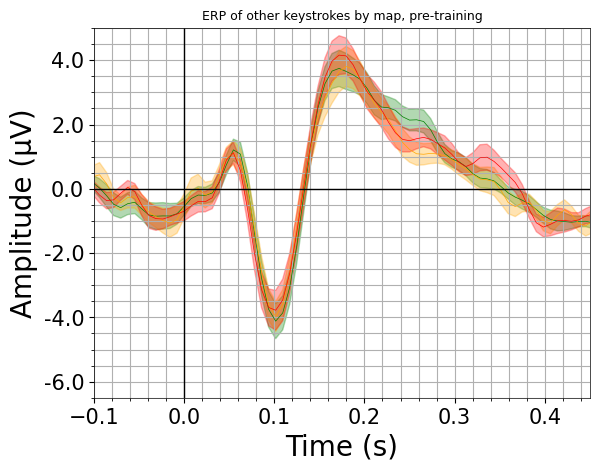

In [ ]:
epochs_df_otherinv = find_firsts_bymap(epochs_df_inv, epochs_df_others)
epochs_df_othershinv = find_firsts_bymap(epochs_df_shinv, epochs_df_others)
epochs_df_othernorm = find_firsts_bymap(epochs_df_norm, epochs_df_others)

period = 'pre'
ch_to_plot = ['Fz']
ch_idx = ch_index(ch_to_plot)

mean_invother, sem_invother = find_mean_sem_eps(epochs_df_otherinv.query(f'period == "{period}"'), ch_idx)
mean_shinvother, sem_shinvother = find_mean_sem_eps(epochs_df_othershinv.query(f'period == "{period}"'), ch_idx)
mean_normother, sem_normother = find_mean_sem_eps(epochs_df_othernorm.query(f'period == "{period}"'), ch_idx)

plot_mean_sem(erp_times, mean_invother, sem_invother, color='green', label='inv')
plot_mean_sem(erp_times, mean_shinvother, sem_shinvother, color='orange', label='shinv')
plot_mean_sem(erp_times, mean_normother, sem_normother, color='red', label='norm')

config_erp_plot()
plt.title(f'ERP of other keystrokes by map, {period}-training')
plt.minorticks_on()

## Cluster permutation test, f-o pre-post

In [101]:
# ASSEMBLE DATA SORTING FIRSTS AND OTHERS BY KEYBOARD, PERIOD
periods = ['pre', 'post']

dfs = {
    'inv_f': epochs_df_firstinv,
    'shinv_f': epochs_df_firstshinv,
    'norm_f': epochs_df_firstnorm,
    'inv_o': epochs_df_otherinv,
    'shinv_o': epochs_df_othershinv,
    'norm_o': epochs_df_othernorm
}

ch = ch_idx[0]

data = {
    (cond, period): np.stack([
        df_period.iloc[i]['epochs'][:, ch, :].mean(axis=0)
        for i in range(len(df_period))
    ])
    for cond, df in dfs.items()
    for period in periods
    for df_period in [df.query("period == @period").reset_index(drop=True)]
}

# GET F-O DIFF BY KEYBOARD
keyboards = ['inv', 'shinv', 'norm']
periods = ['pre', 'post']

diffs_fo_bymap = {
    (kb, period): data[(f'{kb}_f', period)] - data[(f'{kb}_o', period)]
    for kb in keyboards
    for period in periods
}

# GET PREPOST DIFF
diffs_postpre_bymap = {
    kb: diffs_fo_bymap[(kb, 'post')] - diffs_fo_bymap[(kb, 'pre')]
    for kb in keyboards
}

In [102]:
# FIND SIGNIFICANT CLUSTER TIMEPOINTS for pre post diff
T_obs, clusters, cluster_p_values, H0 = permutation_cluster_1samp_test(
    diffs_postpre_bymap['inv'], #shinv and norm not significant
    n_permutations=1000,
    tail=0,            # two‐sided by default; use tail=1 or -1 for one‐sided
    out_type="mask"
    )

sig_idxs = np.where(cluster_p_values < 0.05)[0]
for sig_idx in sig_idxs:
    time_slice = clusters[sig_idx][0]  # Get the time slice object
    start, stop, step = time_slice.start, time_slice.stop, time_slice.step


    print(f'cluster {sig_idx}: p-value = {cluster_p_values[sig_idx]:.4f}, timepoints = {start} to {stop-1}')
    print(f'timepoints: {erp_times[start], erp_times[stop]}')
    print('p-vals:', cluster_p_values)
    

cluster 2: p-value = 0.0290, timepoints = 65 to 70
timepoints: (0.0078125, 0.0546875)
p-vals: [0.461 0.714 0.029]


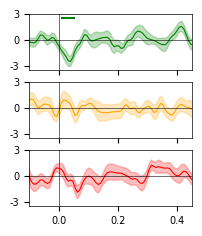

In [ ]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(2.1,2.5),
    sharex=True,
    sharey=True
)

for ax, (key, color) in zip(axes, [
    ('inv', 'green'),
    ('shinv', 'orange'),
    ('norm', 'red')
]):
    data = diffs_postpre_bymap[key]
    mean = data.mean(axis=0)
    sem = data.std(axis=0, ddof=1) / np.sqrt(data.shape[0])

    ax.plot(erp_times, mean, color=color, linewidth=0.8)
    ax.fill_between(
        erp_times, mean - sem, mean + sem,
        color=color, alpha=0.25
    )

    if key == 'inv':
        ax.hlines(2.5e-6, erp_times[start], erp_times[stop],
                  color='green', linewidth=1.5)

    ax.axhline(0, color='black', linewidth=0.4)
    ax.axvline(0, color='black', linewidth=0.4)

    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f'{x * 1e6:.0f}')
    )

    ax.set_xlim(-0.1, 0.45)
    ax.set_ylim(-3.5e-6, 3e-6)
    ax.set_yticks([-3e-6, 0, 3e-6])
# axes[0].set_title('inv', fontsize=5, loc='left')
# axes[1].set_title('shinv', fontsize=5, loc='left')
# axes[2].set_title('norm', fontsize=5, loc='left')

# axes[2].set_xlabel('Time (s)', fontsize=5)
# fig.supylabel('Amplitude (µV)', fontsize=5, x=-0.02)

axes[2].set_xlim(-0.1, 0.45)

# fig.subplots_adjust(
#     left=0.22, right=0.98,
#     top=0.98, bottom=0.22,
#     hspace=0.15
# )

# plt.savefig('./figures/erp_diff_postpre_firsts_others_by_map.svg',
#             bbox_inches='tight')

NORM: 0.070–0.109 s, p=0.033


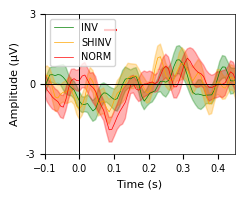

In [82]:
period = 'post'

fig = plt.figure(figsize=(1.9, 1.4))
ax = fig.add_axes([0, 0, 1, 1])

for key, color in [('inv', 'green'), ('shinv', 'orange'), ('norm', 'red')]:
    data = diffs_fo_bymap[(key, period)]

    mean = data.mean(axis=0)
    sem = data.std(axis=0, ddof=1) / np.sqrt(data.shape[0])

    ax.plot(erp_times, mean, color=color, label=key.upper())
    ax.fill_between(
        erp_times, mean - sem, mean + sem,
        color=color, alpha=0.3
    )

    # Cluster permutation test across subjects
    T_obs, clusters, cluster_p_values, H0 = permutation_cluster_1samp_test(
        data,
        n_permutations=1000,
        tail=0,
        out_type='mask'
    )

    # Significant clusters, in the matching map colour
    for cluster, p_value in zip(clusters, cluster_p_values):
        if p_value < 0.05:
            time_slice = cluster[0]
            start, stop = time_slice.start, time_slice.stop

            ax.hlines(
                y=2.7e-6 if key == 'inv' else
                  2.5e-6 if key == 'shinv' else 2.3e-6,
                xmin=erp_times[start],
                xmax=erp_times[stop - 1],
                color=color,
                linewidth=1.5
            )

            print(f'{key.upper()}: {erp_times[start]:.3f}–'
                  f'{erp_times[stop - 1]:.3f} s, p={p_value:.3f}')

ax.legend()
ax.set_xlabel('Time (s)')
ax.set_ylabel('Amplitude (µV)')

ax.axhline(0, color='black', linewidth=0.7)
ax.axvline(0, color='black', linewidth=0.7)

ax.set_xlim(-0.1, 0.45)
ax.set_ylim(-3e-6, 3e-6)
ax.set_yticks([-3e-6, 0, 3e-6])
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x * 1e6:.0f}')
)

plt.savefig(f'./figures/ave_fo_diff_by_map_{period}.svg')

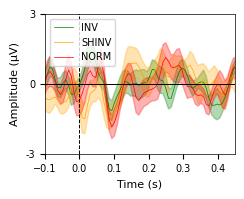

In [74]:
period = 'pre'


fig=plt.figure(figsize=(1.9, 1.4))
ax = fig.add_axes([0,0,1,1])

for key, color in [('inv', 'green'), ('shinv', 'orange'), ('norm', 'red')]:
    data = diffs_fo_bymap[(key, period)]
    mean = data.mean(axis=0)
    sem = data.std(axis=0, ddof=1) / np.sqrt(data.shape[0])

    plt.plot(erp_times, mean, color=color, label=key.upper())
    plt.fill_between(erp_times, mean - sem, mean + sem, color=color, alpha=0.3)

# config_erp_plot()
plt.legend()

# Add labels, legend, and grid
plt.xlabel('Time (s)')
plt.ylabel('Amplitude (µV)')
# plt.title(f'ERP first and others, all participants, {period} training')
plt.hlines(0, -0.5, 0.5, color = 'black', linewidth = 0.7)
plt.vlines(0, -6.5e-6, 5e-6, color = 'black', linestyles= '--', linewidth = 0.7)
# plt.legend(loc = 'upper right')

plt.ticklabel_format(style='plain', axis='y')  # Disable scientific notation
# plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x * 1e6:.1f}'))  # Convert to µV
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{(x * 1e6):.0f}'))  # Convert to µV as integer

plt.xlim(-0.1, 0.45)
plt.ylim(-3e-6, 3e-6)
plt.yticks([-3e-6, 0, 3e-6])

# plt.xticks(fontsize = xtick_fontsize)
# plt.yticks(fontsize = xtick_fontsize)

plt.savefig('./figures/tets.svg')

plt.savefig(f'./figures/ave_fo_diff_by_map_{period}.svg')

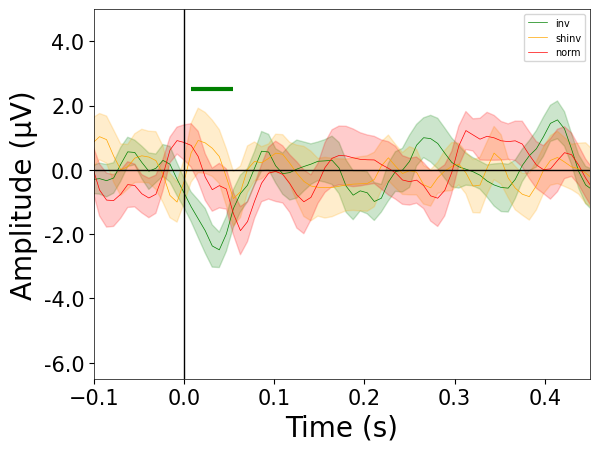

In [22]:
for key, color in [('inv', 'green'), ('shinv', 'orange'), ('norm', 'red')]:
    data = diffs_postpre_bymap[key]
    mean = data.mean(axis=0)
    sem = data.std(axis=0, ddof=1) / np.sqrt(data.shape[0])

    plt.plot(erp_times, mean, color=color, label=key)
    plt.fill_between(erp_times, mean - sem, mean + sem, color=color, alpha=0.2)

config_erp_plot()
plt.hlines(2.5e-6, 0.0078125, 0.0546875, color = 'green', linewidth = 3)

plt.legend()

## Plot topos by map

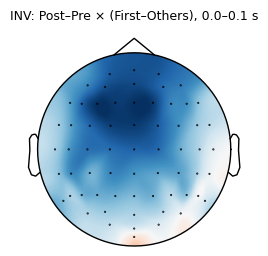

In [ ]:
# raw version without stats
data_all = {
    (cond, period): np.stack([
        df_period.iloc[i]['epochs'].mean(axis=0)
        for i in range(len(df_period))
    ])
    for cond, df in dfs.items()
    for period in periods
    for df_period in [df.query("period == @period").reset_index(drop=True)]
}

diffs_fo_all = {
    (kb, period): data_all[(f'{kb}_f', period)] - data_all[(f'{kb}_o', period)]
    for kb in keyboards
    for period in periods
}

diffs_postpre_all = {
    kb: diffs_fo_all[(kb, 'post')] - diffs_fo_all[(kb, 'pre')]
    for kb in keyboards
}


tmin, tmax = 0.01, 0.06

time_idx = (erp_times >= tmin) & (erp_times <= tmax)

# Average across subjects and the selected time window
topo_data = diffs_postpre_all['inv'][:, :64, time_idx].mean(axis=(0, 2))


info = load_ep_info()
fig, ax = plt.subplots(figsize=(3, 3))
mne.viz.plot_topomap(
    topo_data,
    info,
    ch_type='eeg',
    axes=ax,
    show=False,
    cmap='RdBu_r',
    contours=0
)
ax.set_title(f'INV: Post–Pre × (First–Others), {tmin:.1f}–{tmax:.1f} s')
plt.show()

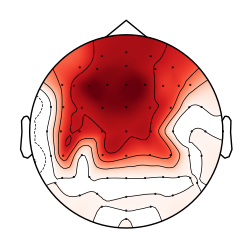

In [33]:
diff_diff = diffs_postpre_all['inv'][:, :64, time_idx].mean(axis=2)

t_values, p_pp = t_over_channels(diff_diff)
mask = np.asarray(p_pp) < 0.05

diffs_pp_t = np.abs(diff_diff.mean(axis=0))
diffs_pp_t[~mask] = 0

cmap = plt.cm.Reds.copy()
cmap.set_under('white')

fig, ax = plt.subplots(figsize=(3, 3))
mne.viz.plot_topomap(
    diffs_pp_t,
    info,
    cmap=cmap,
    vlim=(1e-20, diffs_pp_t.max()),
    # contours=0,
    axes=ax,
    show=False
)
# ax.set_title('INV: Post–Pre × (First–Others)')
plt.savefig('./figures/topomap_inv_postpre_firsts_others.svg')


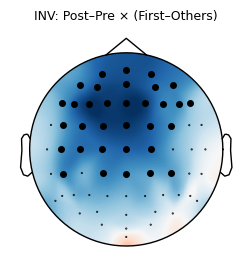

In [ ]:
# highlight channels with dots
# Shape: (n_subjects, n_channels, n_times)
diff_diff = diffs_postpre_all['inv'][:, :64, time_idx].mean(axis=2)

# Test each channel across subjects
t_values, p_pp = t_over_channels(diff_diff)

# Grand-average interaction
diffs_pp_t = diff_diff.mean(axis=0)

# Mask nonsignificant channels
mask = np.asarray(p_pp) < 0.05

fig, ax = plt.subplots(figsize=(3, 3))
mne.viz.plot_topomap(
    diffs_pp_t,
    info,
    mask=mask,
    mask_params=dict(marker='o', markerfacecolor='black',
                     markeredgecolor='black', markersize=4),
    cmap='RdBu_r',
    contours=0,
    axes=ax,
    show=False
)
ax.set_title('INV: Post–Pre × (First–Others)')
plt.show()